# Main Evaluation Report: The Sharpness Quest

## Setup and Imports

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import NearestNeighbors
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
from tqdm import tqdm
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os
import scipy
import seaborn as sns
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings
from models import cEncoder, cDecoder, cVAE, cDiscriminator, SimpleClassifier, compute_vae_loss, load_dataset

# Fix random seed for reproducibility at the top
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
os.makedirs('plot', exist_ok=True)


Device: cuda:0


## Data Loading

We load only the **test split** of the custom MNIST dataset for evaluation. This ensures we are measuring generalisation performance on data the models have never seen during training.

In [40]:
data_custom = load_dataset('mnist_custom')
test_dataset = torch.utils.data.TensorDataset(data_custom['test_images'], data_custom['test_labels'])
test_dataloader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

def get_batch(batch, device, num_classes=10):
    x = batch[0].to(device)
    cond = batch[1].to(device)
    cond_onehot = F.one_hot(cond, num_classes=num_classes).float()
    return x, cond_onehot


## Dataset Inspection

A quick visual check of the test data to confirm the 20×20 pixel format and class label correctness.

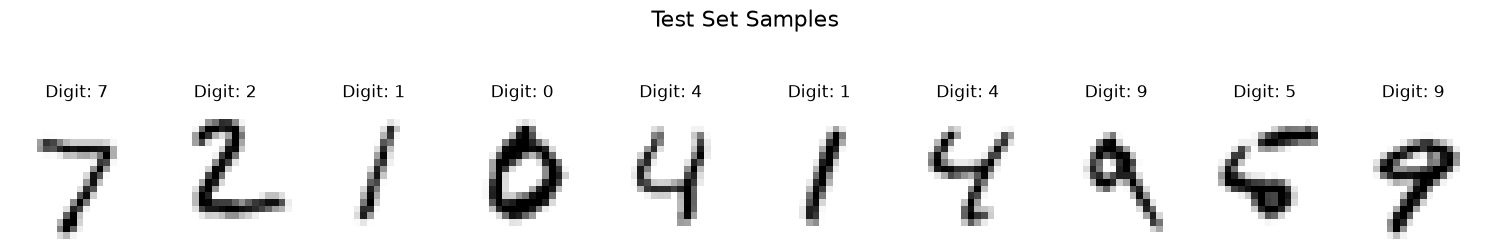

In [41]:
# Examine some samples from the custom dataset to understand the data distribution
batch_x, batch_y = next(iter(test_dataloader))
fig, axes = plt.subplots(1, 10, figsize=(15, 3))
for i in range(10):
    axes[i].imshow(batch_x[i].squeeze(), cmap='gray')
    axes[i].set_title(f'Digit: {batch_y[i].item()}', fontsize=12)
    axes[i].axis('off')
plt.suptitle('Test Set Samples', fontsize=16)
plt.tight_layout()
plt.show()


## Model Loading

We instantiate both cVAE architectures (identical structure, z=7) and load the pre-trained weights saved during the training phase. Both models are set to evaluation mode to disable dropout and batch normalisation dynamics.

In [42]:
z_dim = 7
num_classes = 10

baseline_model = cVAE(z_dim, num_classes).to(device)
sd = torch.load('assets/baseline_cvae_weights.pt', map_location=device, weights_only=True)
if 'encoder.encoder_head.0.weight' in sd:
    sd['encoder.encoder_head.weight'] = sd.pop('encoder.encoder_head.0.weight')
    sd['encoder.encoder_head.bias'] = sd.pop('encoder.encoder_head.0.bias')
baseline_model.load_state_dict(sd)
baseline_model.eval()

modified_model = cVAE(z_dim, num_classes).to(device)
modified_model.load_state_dict(torch.load('assets/modified_cvae_weights.pt', map_location=device, weights_only=True))
modified_model.eval()
print("Successfully loaded weights for both models!")


Successfully loaded weights for both models!


## Standalone Classifier

We load a pre-trained `SimpleClassifier` (a small CNN trained on real MNIST data for 3 epochs). This classifier serves as an independent judge — it was never exposed to any VAE-generated images during its own training. We use it to:
- Measure **semantic consistency** (can it recognise the generated digits?)
- Extract **latent features** for computing Fréchet Classifier Distance (FCD)

In [ ]:
classifier = SimpleClassifier().to(device)
classifier.load_state_dict(torch.load('assets/classifier_weights.pt', map_location=device, weights_only=True))
classifier.eval()
print('Loaded classifier weights!')

Loaded classifier weights!


## Conditional Generation Grid (12×10 per Model)

For each model, we generate 12 samples per digit class (0–9) using the **same random latent vectors**, producing 120 images per model. Using identical z vectors ensures any visual differences are purely due to the model's learned decoder, not randomness.

The resulting grids are saved as PNG files for inclusion in the technical report.

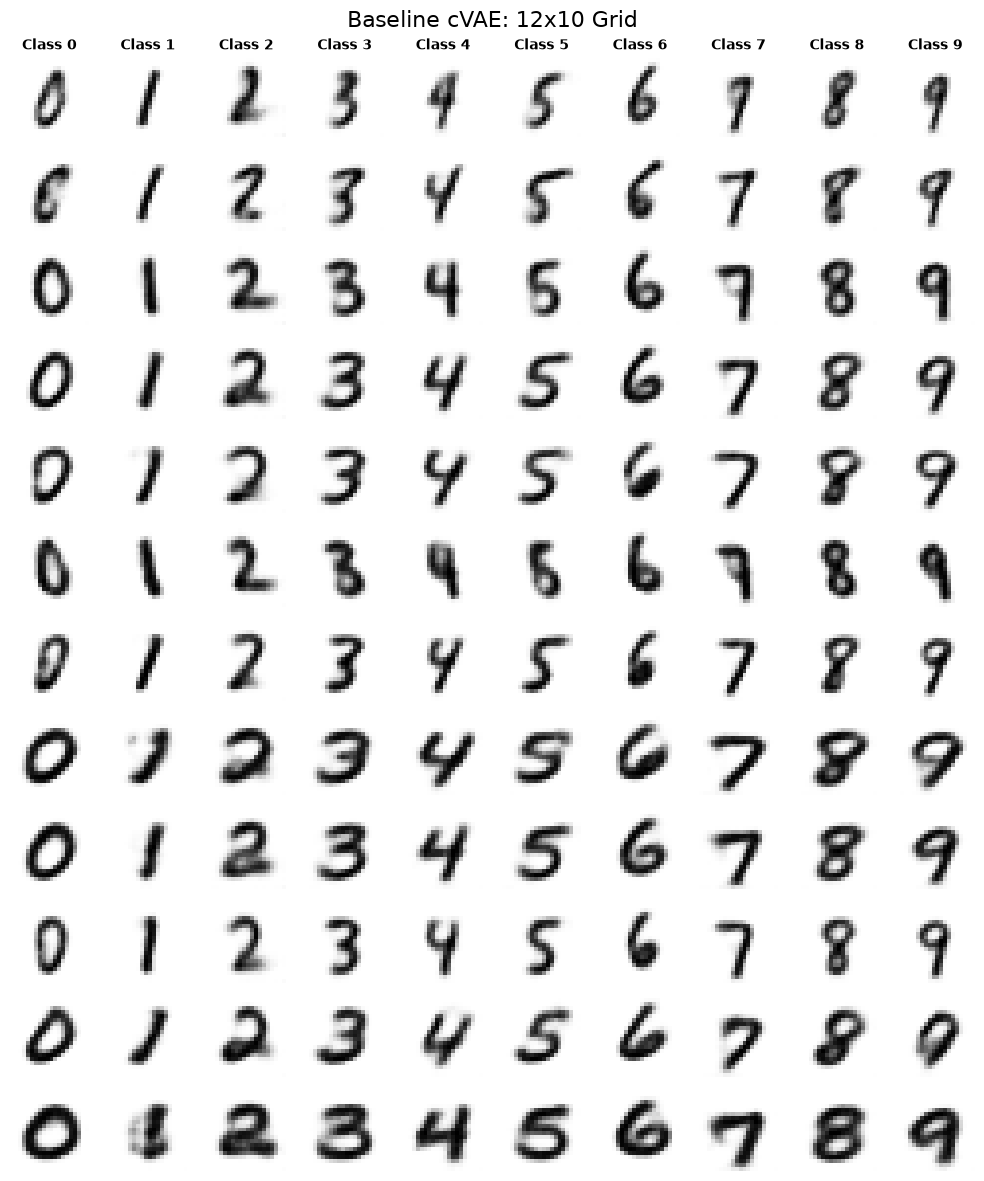

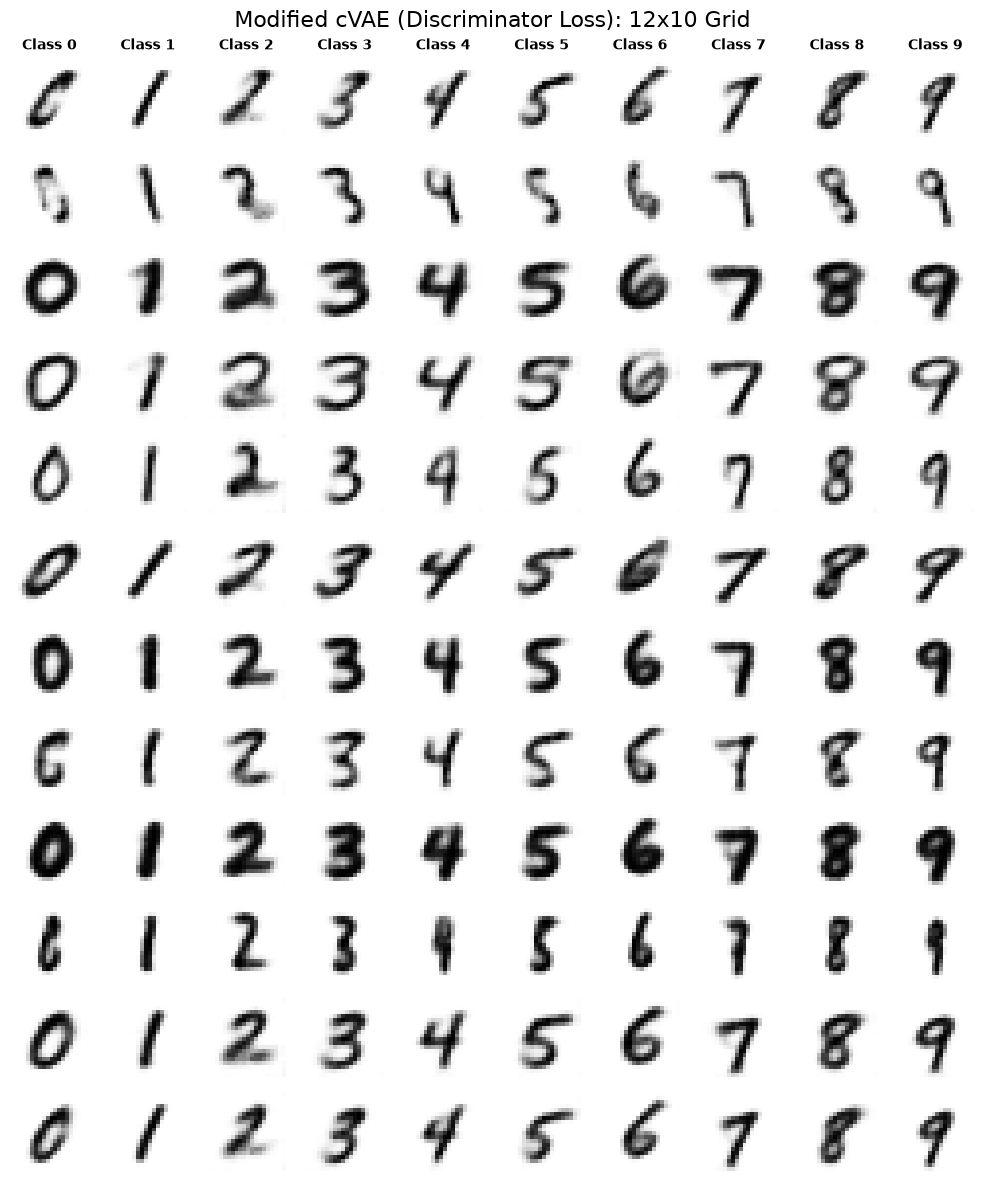

In [44]:
def generate_grid(model, num_samples=12):
    
    all_xhat = []
    z_cond = torch.randn(num_samples, z_dim).to(device)
    
    for c in range(10):
        cond = F.one_hot(torch.tensor([c]*num_samples), num_classes=10).float().to(device)
        with torch.no_grad():
            x_hat = model.decode(z_cond, cond).cpu()
        all_xhat.append(x_hat)
        
    all_xhat = torch.stack(all_xhat) # [10, 12, 1, 28, 28]
    return all_xhat

def plot_and_save_grid(all_xhat, title, filename):
    fig, axes = plt.subplots(12, 10, figsize=(10, 12))
    for c in range(10):
        for i in range(12):
            axes[i, c].imshow(all_xhat[c, i].squeeze(), cmap='gray')
            axes[i, c].axis('off')
            if i == 0:
                axes[i, c].set_title(f'Class {c}', fontsize=10, fontweight='bold')
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(f'plot/{filename}')
    plt.show()

base_grid = generate_grid(baseline_model)
mod_grid = generate_grid(modified_model)

plot_and_save_grid(base_grid, "Baseline cVAE: 12x10 Grid", "baseline_grid.png")
plot_and_save_grid(mod_grid, "Modified cVAE (Discriminator Loss): 12x10 Grid", "modified_grid.png")


## Metric Visualisation Utility

In [45]:
def plot_metric_with_samples(base_metric, mod_metric, base_samples, mod_samples, ylabel, title, filename, lower_better=False):
    fig = plt.figure(figsize=(12, 4))
    
    ax1 = plt.subplot(1, 3, 1)
    grid_b = make_grid(base_samples[:25], nrow=5, padding=2).permute(1, 2, 0).cpu().numpy()
    ax1.imshow(grid_b, cmap='gray')
    ax1.set_title('Baseline Samples', fontsize=14)
    ax1.axis('off')
    
    ax2 = plt.subplot(1, 3, 2)
    grid_m = make_grid(mod_samples[:25], nrow=5, padding=2).permute(1, 2, 0).cpu().numpy()
    ax2.imshow(grid_m, cmap='gray')
    ax2.set_title('Modified Samples', fontsize=14)
    ax2.axis('off')
    
    ax3 = plt.subplot(1, 3, 3)
    bars = ax3.bar(['Baseline', 'Modified'], [base_metric, mod_metric], color=['blue', 'orange'])
    ax3.set_ylabel(ylabel, fontsize=12)
    ax3.set_title(title, fontsize=14)
    if 'Accuracy' in ylabel: ax3.set_ylim(0, 100)
    
    for bar in bars:
        yval = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2, yval + (0.01 * yval), f'{yval:.2f}', ha='center', va='bottom', fontsize=12)
        
    plt.tight_layout()
    plt.savefig(f'plot/{filename}')
    plt.show()

# Flatten grids for random sampling
base_flat = base_grid.view(-1, 1, 20, 20)
mod_flat = mod_grid.view(-1, 1, 20, 20)
# Random subset
idx = torch.randperm(120)[:25]
sample_b = base_flat[idx]
sample_m = mod_flat[idx]


## Sharpness Evaluation (Laplacian Variance)

### Methodology
We compute the **Laplacian variance** of each generated image — a classical edge-detection metric. The Laplacian operator highlights intensity transitions (edges), and its variance measures how much edge content exists:
- **Higher variance → sharper images** (more defined edges and strokes)
- **Lower variance → blurrier images** (smoother, washed-out appearance)

### Interpretation
If the hypothesis holds, the modified model's Laplacian variance should be significantly higher than the baseline's, confirming that the discriminator loss produces images with more defined edges.


Baseline Sharpness: 0.08
Modified Sharpness: 0.07


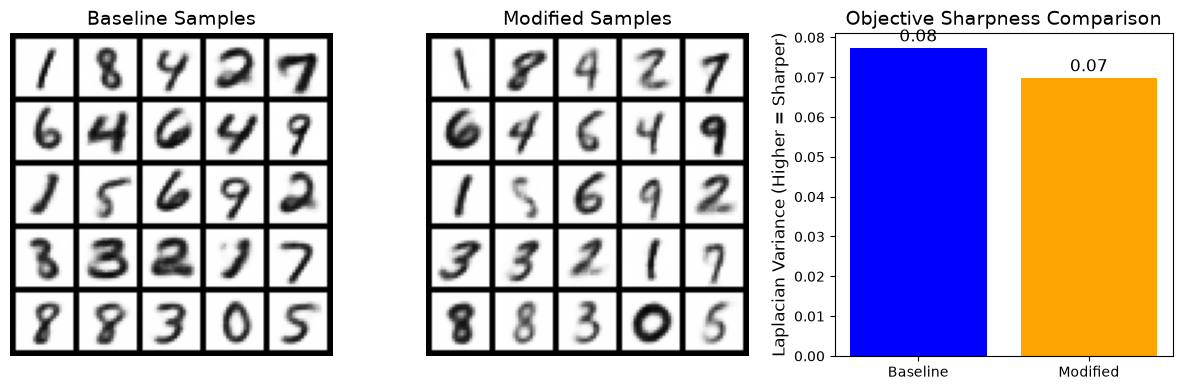

In [46]:
def compute_laplacian_variance(images):
    images_np = images.view(-1, 20, 20).cpu().numpy()
    variances = [cv2.Laplacian(img, cv2.CV_32F).var() for img in images_np]
    return np.mean(variances)

base_sharpness = compute_laplacian_variance(base_grid)
mod_sharpness = compute_laplacian_variance(mod_grid)
print(f'Baseline Sharpness: {base_sharpness:.2f}')
print(f'Modified Sharpness: {mod_sharpness:.2f}')
plot_metric_with_samples(base_sharpness, mod_sharpness, sample_b, sample_m, 'Laplacian Variance (Higher = Sharper)', 'Objective Sharpness Comparison', 'sharpness_comparison.png')


## Semantic Consistency Evaluation

### Methodology
We generate 1000 random samples from each model (100 per class) and classify them using the standalone classifier. The **accuracy** measures how reliably the generated digits are recognisable as their intended class:
- **High accuracy** → The model generates digits that clearly match their conditioning label
- **Low accuracy** → The model produces ambiguous or incorrect digits

### Interpretation
A good generative model should maintain high consistency. If the discriminator loss degrades consistency (by introducing artefacts or mode confusion), it would be a significant trade-off against any sharpness gains.


Baseline Class Consistency Accuracy: 96.27%
Modified Class Consistency Accuracy: 96.34%


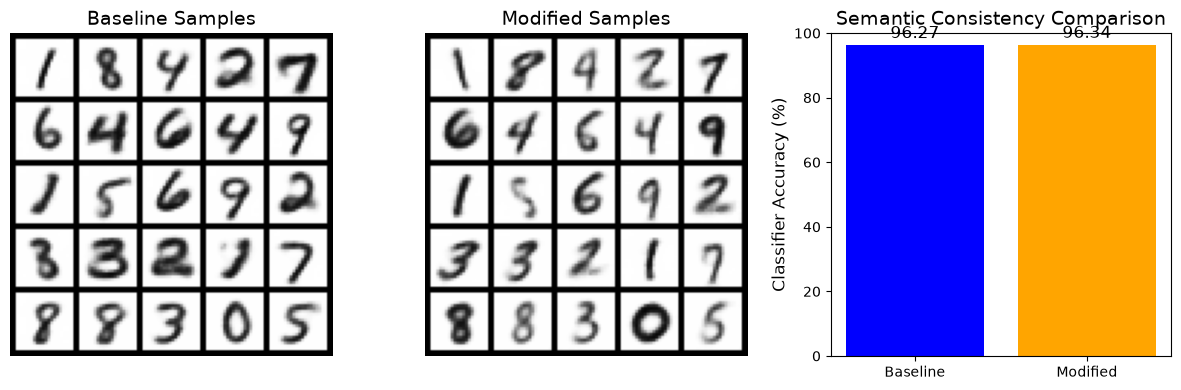

In [47]:
def evaluate_consistency(model, classifier, n_samples=1000):
    classifier.eval()
    correct = 0
    total = n_samples * 10
    for c in range(10):
        z = torch.randn(n_samples, z_dim).to(device)
        cond = F.one_hot(torch.tensor([c]*n_samples), num_classes=10).float().to(device)
        with torch.no_grad():
            x_hat = model.decode(z, cond)
            preds = classifier(x_hat).argmax(dim=1)
            correct += (preds == c).sum().item()
    return (correct / total) * 100

base_acc = evaluate_consistency(baseline_model, classifier)
mod_acc = evaluate_consistency(modified_model, classifier)
print(f'Baseline Class Consistency Accuracy: {base_acc:.2f}%')
print(f'Modified Class Consistency Accuracy: {mod_acc:.2f}%')
plot_metric_with_samples(base_acc, mod_acc, sample_b, sample_m, 'Classifier Accuracy (%)', 'Semantic Consistency Comparison', 'consistency_comparison.png')


## Fréchet Classifier Distance (FCD)

### Methodology
FCD is analogous to FID (Fréchet Inception Distance) but uses our standalone classifier's penultimate layer features instead of InceptionV3. It measures the distributional distance between real and generated images in feature space:
$$\text{FCD} = \|\mu_r - \mu_g\|^2 + \text{Tr}(\Sigma_r + \Sigma_g - 2(\Sigma_r \Sigma_g)^{1/2})$$

- **Lower FCD → better** (generated distribution is closer to real data)
- **Higher FCD → worse** (generated images deviate from real data statistics)

### Interpretation
If the modified model achieves a lower FCD, it means the discriminator loss helps the generator produce images whose statistical properties better match real data — a strong indicator of improved overall quality.


Baseline FCD: 6.97 | Precision: 0.7664 | Recall: 0.2201
Modified FCD: 7.20 | Precision: 0.7853 | Recall: 0.1708


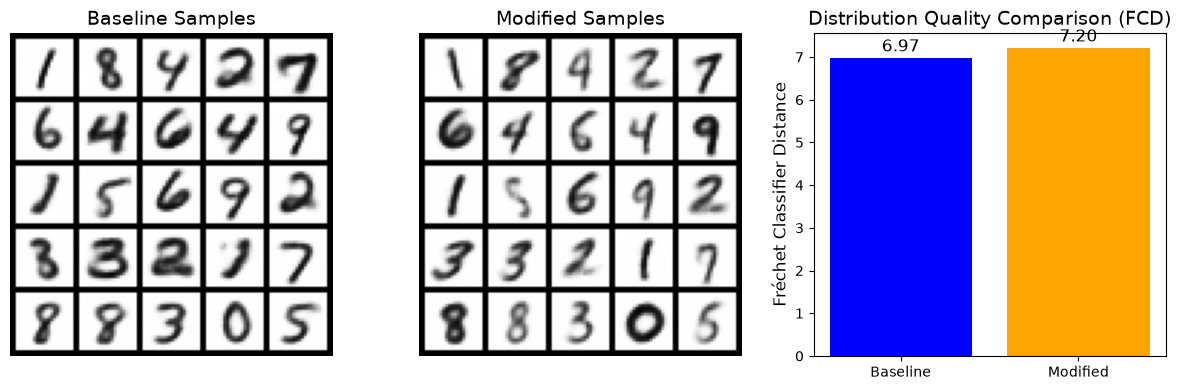

In [48]:
def extract_features(dataloader, classifier):
    features = []
    with torch.no_grad():
        for x, _ in dataloader:
            f = classifier.extract_features(x.to(device)).view(x.size(0), -1)
            features.append(f.cpu().numpy())
    return np.concatenate(features, axis=0)

def extract_fake_features(model, classifier, n_samples=10000):
    features = []
    with torch.no_grad():
        for _ in range(n_samples // 100):
            z = torch.randn(100, z_dim).to(device)
            c = torch.randint(0, 10, (100,))
            cond = F.one_hot(c, 10).float().to(device)
            x_hat = model.decode(z, cond)
            f = classifier.extract_features(x_hat).view(100, -1)
            features.append(f.cpu().numpy())
    return np.concatenate(features, axis=0)

real_features = extract_features(test_dataloader, classifier)
base_features = extract_fake_features(baseline_model, classifier)
mod_features = extract_fake_features(modified_model, classifier)

def compute_frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    diff = mu1 - mu2
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        covmean = scipy.linalg.sqrtm(sigma1.dot(sigma2))
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = scipy.linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
    if np.iscomplexobj(covmean): covmean = covmean.real
    return diff.dot(diff) + np.trace(sigma1) + np.trace(sigma2) - 2 * np.trace(covmean)

mu_real, sig_real = np.mean(real_features, axis=0), np.cov(real_features, rowvar=False)
mu_base, sig_base = np.mean(base_features, axis=0), np.cov(base_features, rowvar=False)
mu_mod, sig_mod = np.mean(mod_features, axis=0), np.cov(mod_features, rowvar=False)

fcd_base = compute_frechet_distance(mu_real, sig_real, mu_base, sig_base)
fcd_mod = compute_frechet_distance(mu_real, sig_real, mu_mod, sig_mod)

def calculate_precision_recall(real_f, fake_f, k=3):
    nn_real = NearestNeighbors(n_neighbors=k+1).fit(real_f)
    dist_real, _ = nn_real.kneighbors(real_f)
    real_radii = dist_real[:, -1]
    nn_fake = NearestNeighbors(n_neighbors=k+1).fit(fake_f)
    dist_fake, _ = nn_fake.kneighbors(fake_f)
    fake_radii = dist_fake[:, -1]
    nn_real_to_fake = NearestNeighbors(n_neighbors=1).fit(real_f)
    dist_fake_to_real, idx_fake_to_real = nn_real_to_fake.kneighbors(fake_f)
    precision = np.mean(dist_fake_to_real[:, 0] <= real_radii[idx_fake_to_real[:, 0]])
    nn_fake_to_real = NearestNeighbors(n_neighbors=1).fit(fake_f)
    dist_real_to_fake, idx_real_to_fake = nn_fake_to_real.kneighbors(real_f)
    recall = np.mean(dist_real_to_fake[:, 0] <= fake_radii[idx_real_to_fake[:, 0]])
    return precision, recall

p_base, r_base = calculate_precision_recall(real_features, base_features)
p_mod, r_mod = calculate_precision_recall(real_features, mod_features)

print(f'Baseline FCD: {fcd_base:.2f} | Precision: {p_base:.4f} | Recall: {r_base:.4f}')
print(f'Modified FCD: {fcd_mod:.2f} | Precision: {p_mod:.4f} | Recall: {r_mod:.4f}')
plot_metric_with_samples(fcd_base, fcd_mod, sample_b, sample_m, 'Fréchet Classifier Distance', 'Distribution Quality Comparison (FCD)', 'fcd_comparison.png', lower_better=True)


## Reconstruction Confusion Matrices

### Methodology
We pass real test images through each model's encoder→decoder pipeline, then classify the reconstructions with the standalone classifier. The confusion matrix reveals:
- **Diagonal dominance** → The model faithfully preserves digit identity during reconstruction
- **Off-diagonal entries** → Systematic confusions (e.g., 3s reconstructed as 8s)

### Interpretation
This tests whether the discriminator loss helps or hinders the model's ability to preserve semantic content during the encode-decode cycle.

Classifying Modified: 100%|██████████| 10/10 [00:00<00:00, 12.97it/s]


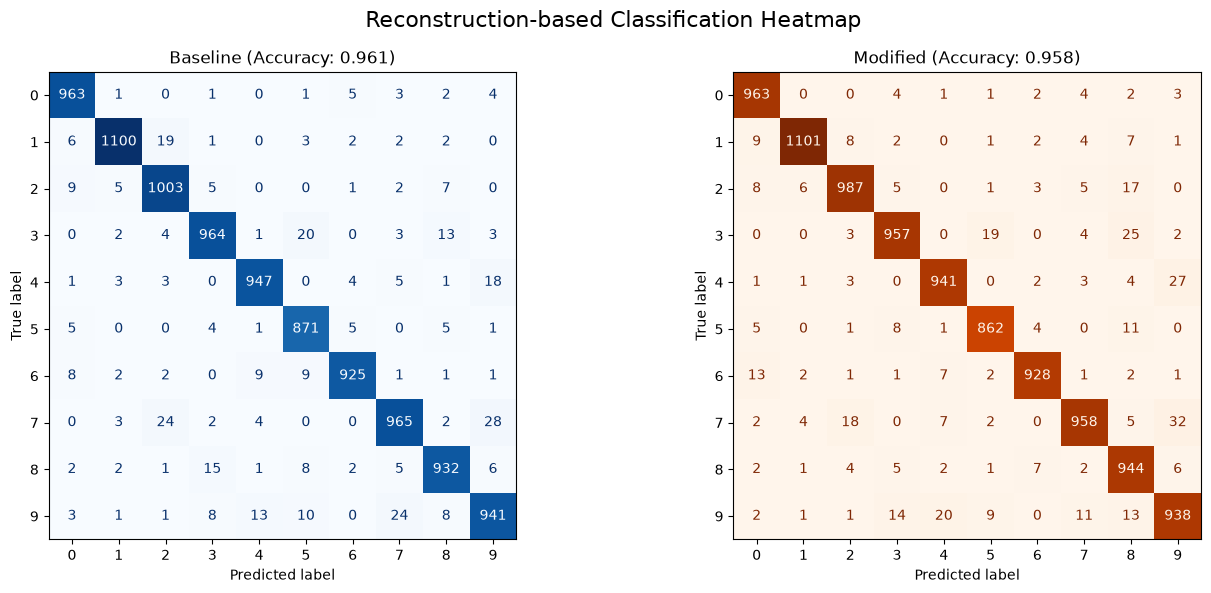

In [49]:

def plot_reconstruction_confusion_matrix(model, title):
    model.eval()
    all_labels, all_preds = [], []
    with torch.no_grad():
        for batch in tqdm(test_dataloader, file=sys.stdout, desc=f"Classifying {title}"):
            x, cond = get_batch(batch, device)
            errors = []
            for y_class in range(10):
                y_onehot = F.one_hot(torch.tensor([y_class]*x.size(0), device=device), 10).float()
                mu, _ = model.encoder(x, y_onehot)
                x_hat = model.decode(mu, y_onehot)
                error = ((x - x_hat)**2).flatten(1).sum(1)
                errors.append(error)
            
            errors = torch.stack(errors, dim=1)
            preds = torch.argmin(errors, dim=1)
            all_preds.append(preds.cpu())
            all_labels.append(torch.argmax(cond, dim=1).cpu())
            
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    cm = confusion_matrix(all_labels, all_preds)
    acc = cm.diagonal().sum() / float(cm.sum())
    
    return cm, acc

cm_base, acc_base = plot_reconstruction_confusion_matrix(baseline_model, "Baseline")
cm_mod, acc_mod = plot_reconstruction_confusion_matrix(modified_model, "Modified")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm_base)
disp1.plot(cmap=plt.cm.Blues, ax=axes[0], colorbar=False)
axes[0].set_title(f"Baseline (Accuracy: {acc_base:.3f})")

disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_mod)
disp2.plot(cmap=plt.cm.Oranges, ax=axes[1], colorbar=False)
axes[1].set_title(f"Modified (Accuracy: {acc_mod:.3f})")

plt.suptitle("Reconstruction-based Classification Heatmap", fontsize=16)
plt.tight_layout()
plt.savefig('plot/reconstruction_classification.png')
plt.show()


## Latent Space Analysis

To understand the internal representations learned by each model, we extract the latent variables (μ, σ) from the encoder for all test images and analyse their structure.

### 2D Histogram of Latent Means
Shows the density distribution of the first two latent dimensions. A well-structured latent space should show distinct clustering patterns.

In [50]:
def extract_latent_variables(model):
    latent_mu, latent_std, classes = [], [], []
    model.eval()
    with torch.no_grad():
        for batch in tqdm(test_dataloader, file=sys.stdout, desc="Extracting Latents"):
            x, cond = get_batch(batch, device)
            mu, logvar = model.encoder(x, cond)
            latent_mu.append(mu.cpu().numpy())
            latent_std.append(torch.exp(0.5 * logvar).cpu().numpy())
            classes.append(torch.argmax(cond, dim=1).cpu().numpy())
            
    return np.concatenate(latent_mu, axis=0), np.concatenate(latent_std, axis=0), np.concatenate(classes, axis=0)

base_mu, base_std, test_classes = extract_latent_variables(baseline_model)
mod_mu, mod_std, _ = extract_latent_variables(modified_model)


Extracting Latents: 100%|██████████| 10/10 [00:00<00:00, 95.65it/s]


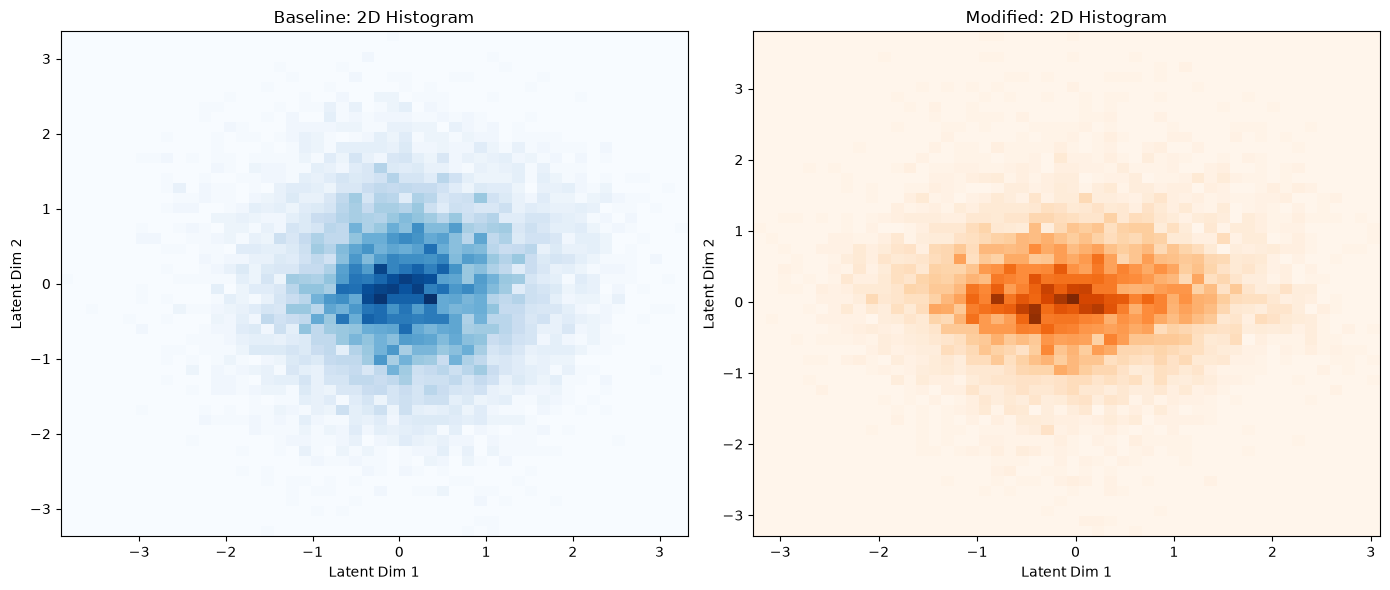

In [ ]:
# Visualization 1: 2D Histogram of Latent Means
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].hist2d(base_mu[:, 0], base_mu[:, 1], bins=50, cmap='Blues')
axes[0].set_title('Baseline: 2D Histogram')
axes[0].set_xlabel('Latent Dim 1'); axes[0].set_ylabel('Latent Dim 2')

axes[1].hist2d(mod_mu[:, 0], mod_mu[:, 1], bins=50, cmap='Oranges')
axes[1].set_title('Modified: 2D Histogram')
axes[1].set_xlabel('Latent Dim 1'); axes[1].set_ylabel('Latent Dim 2')
plt.tight_layout()
plt.savefig('plot/latent_2d_hist.png')
plt.show()

### Scatterplot of Latent Means (Coloured by Class)

Each point represents a test image's latent encoding, coloured by its digit class. Well-separated clusters indicate the model has learned a class-discriminative latent space.

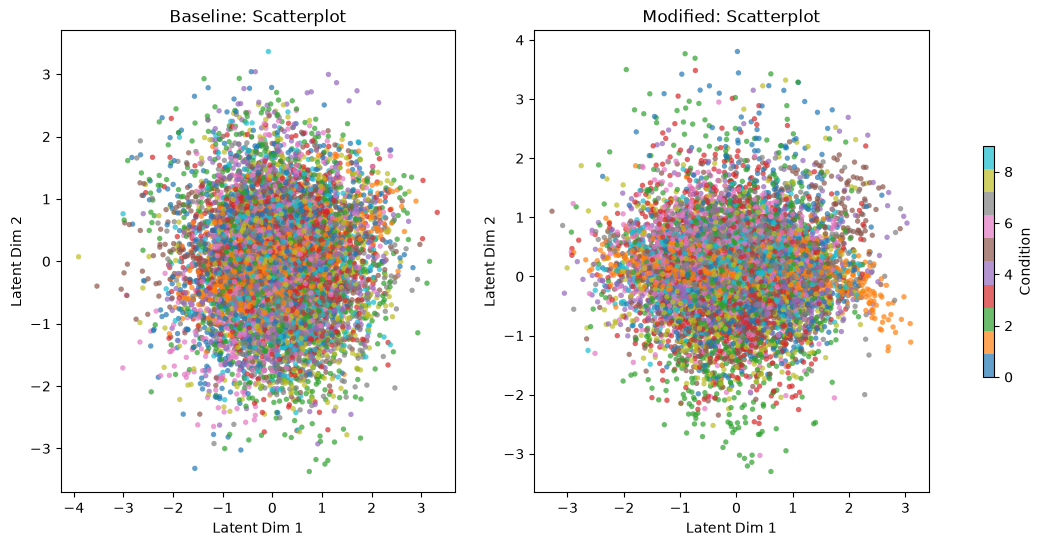

In [52]:
# Visualization 2: Scatterplot of Latent Means Colored by Class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
cmap = plt.get_cmap('tab10', 10)
sc1 = axes[0].scatter(base_mu[:, 0], base_mu[:, 1], c=test_classes, cmap=cmap, alpha=0.7, s=15, edgecolor='none')
axes[0].set_title('Baseline: Scatterplot')
axes[0].set_xlabel('Latent Dim 1'); axes[0].set_ylabel('Latent Dim 2')

sc2 = axes[1].scatter(mod_mu[:, 0], mod_mu[:, 1], c=test_classes, cmap=cmap, alpha=0.7, s=15, edgecolor='none')
axes[1].set_title('Modified: Scatterplot')
axes[1].set_xlabel('Latent Dim 1'); axes[1].set_ylabel('Latent Dim 2')

fig.colorbar(sc2, ax=axes.ravel().tolist(), label='Condition', shrink=0.5)
plt.savefig('plot/latent_2d_scatter.png')
plt.show()


### KDE Distributions and Standard Deviations

**Top row**: Kernel Density Estimates of each latent dimension's mean values, comparing baseline vs. modified.
**Bottom row**: Distribution of learned standard deviations — these control how much the model "spreads" each encoding.

A model with tighter σ values tends to produce less diverse but potentially sharper outputs.

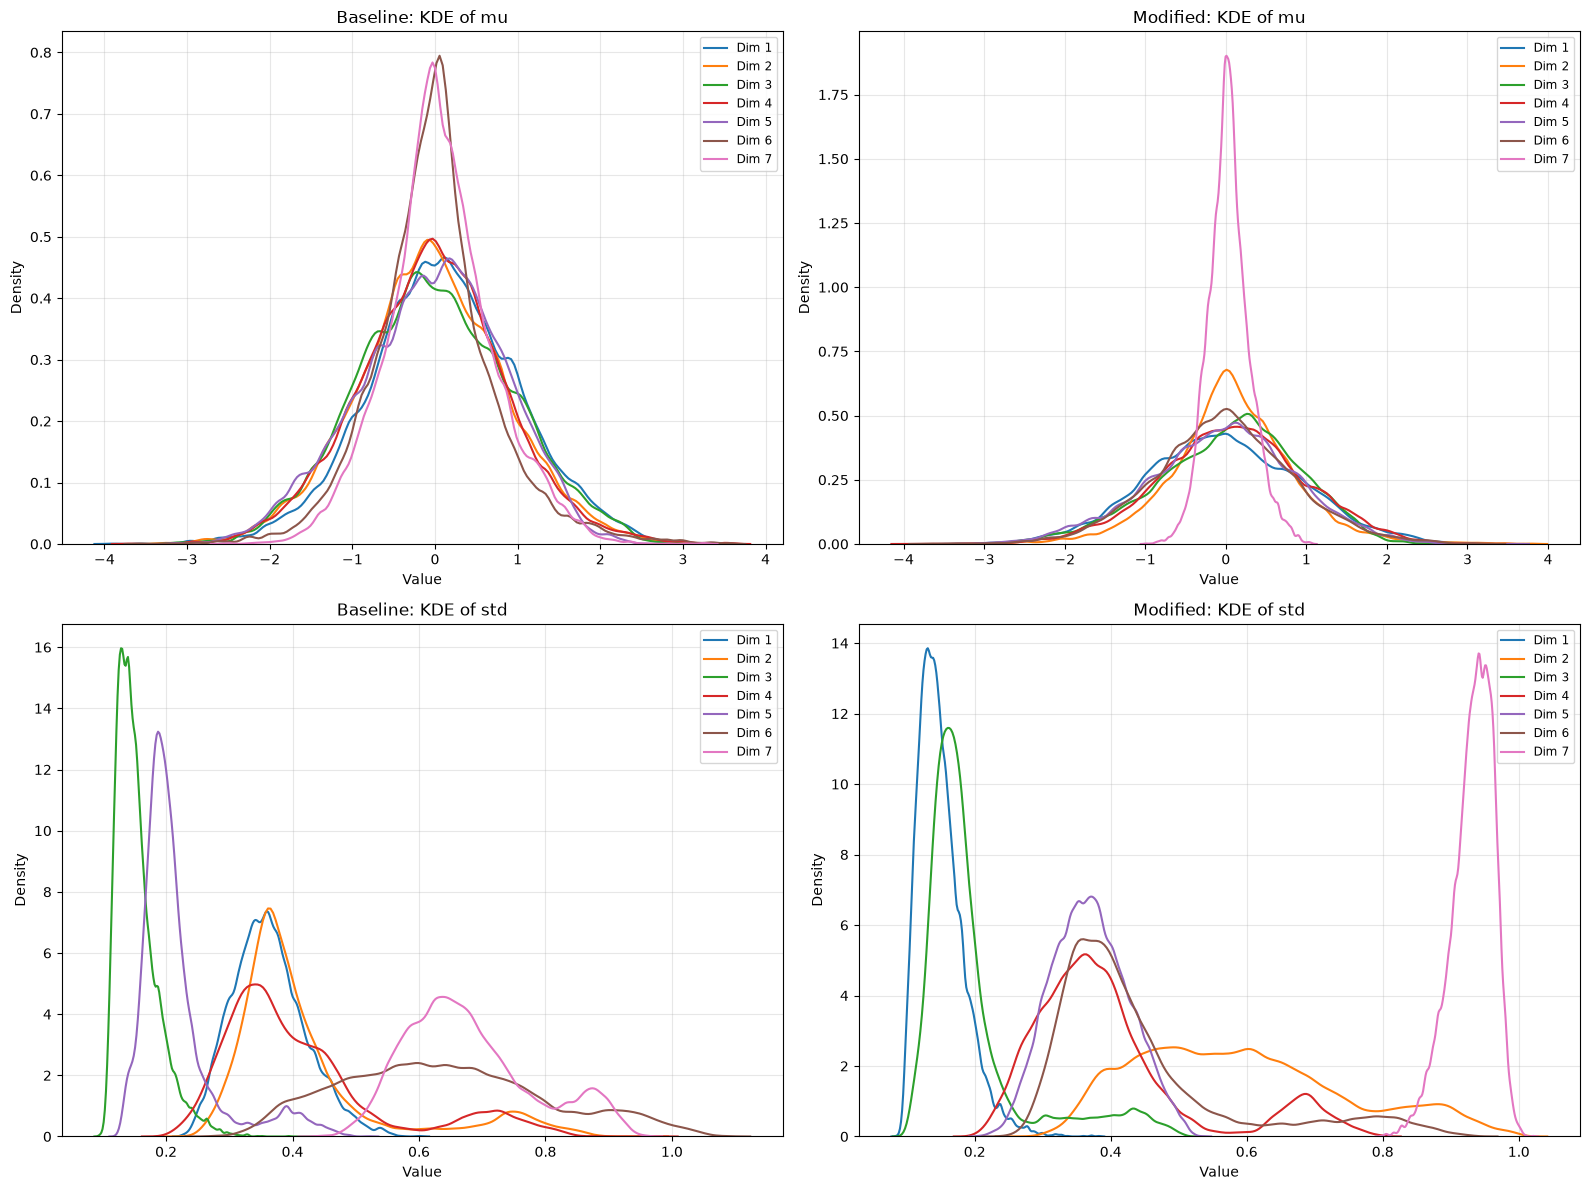

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for i in range(z_dim):
    sns.kdeplot(base_mu[:, i], ax=axes[0, 0], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)
    sns.kdeplot(mod_mu[:, i], ax=axes[0, 1], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)

axes[0, 0].set_title('Baseline: KDE of mu')
axes[0, 1].set_title('Modified: KDE of mu')

for i in range(z_dim):
    sns.kdeplot(base_std[:, i], ax=axes[1, 0], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)
    sns.kdeplot(mod_std[:, i], ax=axes[1, 1], label=f'Dim {i+1}', linewidth=1.5, bw_adjust=0.5)

axes[1, 0].set_title('Baseline: KDE of std')
axes[1, 1].set_title('Modified: KDE of std')

for ax in axes.flat:
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(fontsize='small', loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('plot/latent_kde_analysis.png')
plt.show()


### Angular Analysis of Latent Space
Measures how latent vectors are distributed angularly relative to a reference point. A more uniform angular distribution suggests the model uses the full latent space capacity, while clustering indicates under-utilisation.


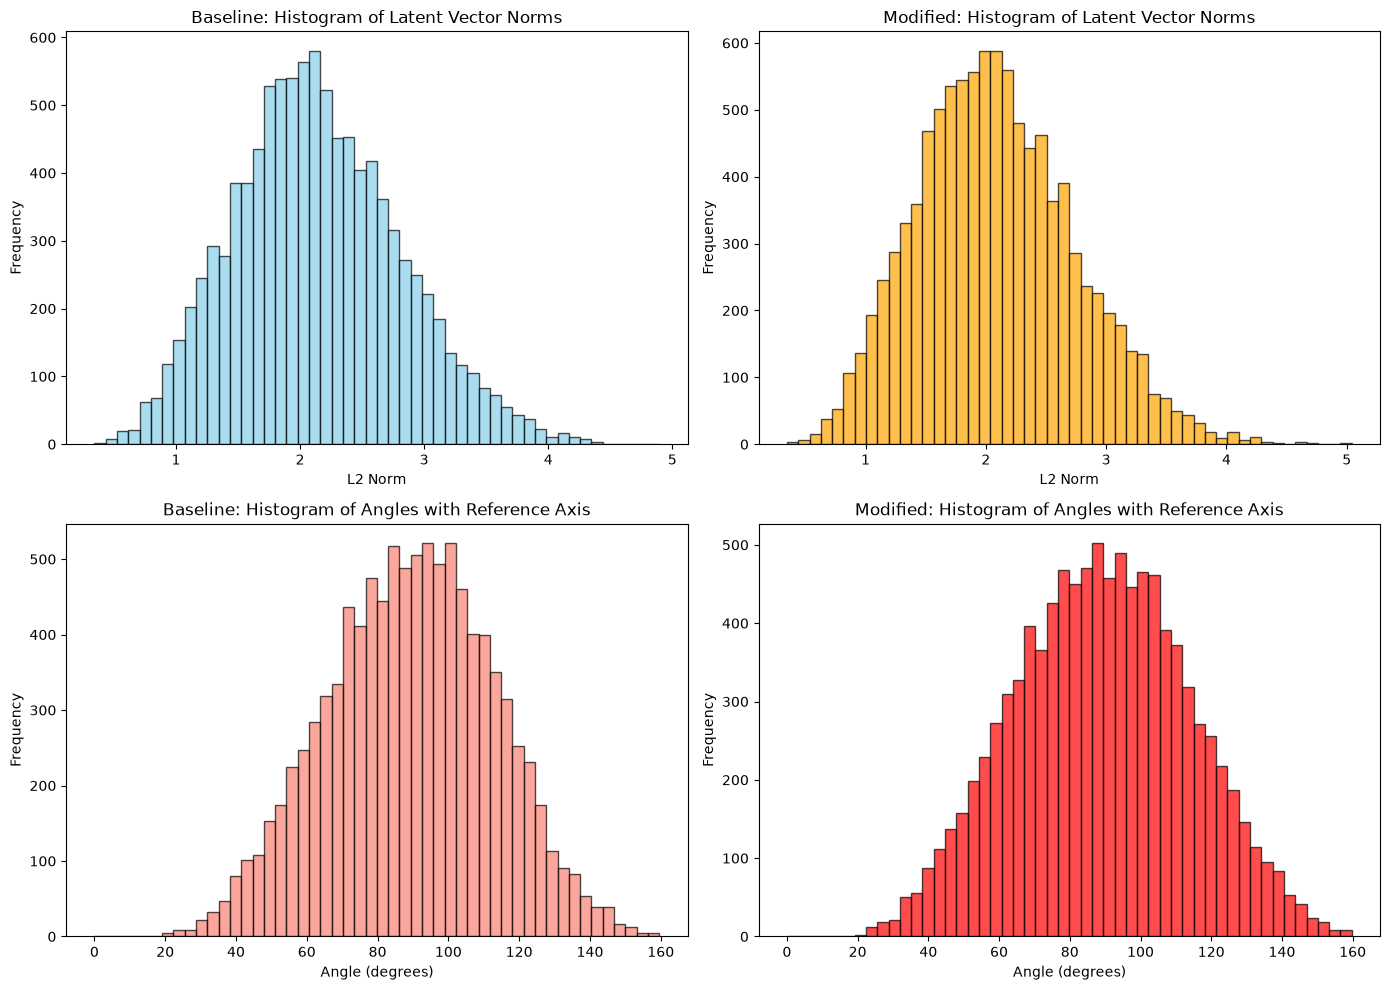

In [54]:
def compute_angles(latents):
    reference = latents[0]
    ref_norm = reference / np.linalg.norm(reference)
    norms = np.linalg.norm(latents, axis=1)
    
    latents_normalized = latents / norms[:, None]
    dot_products = np.clip(np.dot(latents_normalized, ref_norm), -1.0, 1.0)
    angles = np.degrees(np.arccos(dot_products))
    return norms, angles

base_norms, base_angles = compute_angles(base_mu)
mod_norms, mod_angles = compute_angles(mod_mu)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(base_norms, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Baseline: Histogram of Latent Vector Norms')
axes[0, 0].set_xlabel('L2 Norm'); axes[0, 0].set_ylabel('Frequency')

axes[0, 1].hist(mod_norms, bins=50, color='orange', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Modified: Histogram of Latent Vector Norms')
axes[0, 1].set_xlabel('L2 Norm'); axes[0, 1].set_ylabel('Frequency')

axes[1, 0].hist(base_angles, bins=50, color='salmon', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Baseline: Histogram of Angles with Reference Axis')
axes[1, 0].set_xlabel('Angle (degrees)'); axes[1, 0].set_ylabel('Frequency')

axes[1, 1].hist(mod_angles, bins=50, color='red', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Modified: Histogram of Angles with Reference Axis')
axes[1, 1].set_xlabel('Angle (degrees)'); axes[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('plot/latent_norms_angles.png')
plt.show()
